In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl 
from tensorflow import keras
import tensorflow as tf
from pathlib import Path
import random
import glob
from PIL import Image
from keras.models import Sequential
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import  Input, Conv2D, MaxPool2D, Flatten, Dense, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocessing 
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocessing
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenetv2_preprocessing 
from keras import callbacks

In [2]:
train_dataset, validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/training",
    image_size=(224, 224),
    seed = 42,
    validation_split = 0.2,
    subset = "both",
    batch_size=32,
    label_mode="binary"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/testing",
    image_size=(224, 224),
    shuffle=False,
    batch_size=32,
    label_mode="binary"
)

Found 2392 files belonging to 2 classes.
Using 1914 files for training.
Using 478 files for validation.
Found 597 files belonging to 2 classes.


In [3]:
def basemodel(size, activation,padding, dense_activation, optimizer,loss, epoch):
    model = Sequential()
    model.add(Input(shape=(224, 224, 3)))

    model.add(Conv2D(16, kernel_size=size, 
                    activation=activation, 
                    padding=padding))
    model.add(BatchNormalization())
    model.add(MaxPool2D(2))
    model.add(Conv2D(32, kernel_size=size, activation=activation ,padding=padding))
    model.add(MaxPool2D(2))
    model.add(Conv2D(64, kernel_size=size, activation=activation ,padding=padding))
    model.add(MaxPool2D(2))
    model.add(Flatten())
    model.add(Dense(1, activation=dense_activation))

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
    )

    history_basemodel = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs= epoch
    )
    custom_model_results = model.evaluate(test_dataset, return_dict=True)
    return model, history_basemodel, custom_model_results

In [4]:
model, history_basemodel, custom_model_results = basemodel(
    size=3,
    activation="relu",
    padding="same",
    dense_activation="sigmoid",
    optimizer="adam",
    loss="binary_crossentropy",
    epoch=4,
)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 190s 3s/step - accuracy: 0.6740 - f1: 0.6479 - loss: 0.9044 - pr_auc: 0.6774 - precision: 0.7238 - recall: 0.5863 - roc_auc: 0.7247 - val_accuracy: 0.7364 - val_f1: 0.7812 - val_loss: 0.5129 - val_pr_auc: 0.8889 - val_precision: 0.6923 - val_recall: 0.8964 - val_roc_auc: 0.8810
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 104s 2s/step - accuracy: 0.9415 - f1: 0.9430 - loss: 0.1761 - pr_auc: 0.9837 - precision: 0.9392 - recall: 0.9469 - roc_auc: 0.9842 - val_accuracy: 0.6695 - val_f1: 0.7606 - val_loss: 0.7124 - val_pr_auc: 0.9651 - val_precision: 0.6137 - val_recall: 1.0000 - val_roc_auc: 0.9696
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 105s 2s/step - accuracy: 0.9828 - f1: 0.9832 - loss: 0.0578 - pr_auc: 0.9985 - precision: 0.9817 - recall: 0.9847 - roc_auc: 0.9984 - val_accuracy: 0.6715 - val_f1: 0.7618 - val_loss: 0.8706 - val_pr_auc: 0.9679 - val_precision: 0.6152 - val_recall: 1.0000 - val_roc_auc: 0.9800
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - 

In [5]:
model.save("../models/custom_model.keras")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        50,177 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221,413 (864.90 KB)

 Trainable params: 73,793 (288.25 KB)

 Non-trainable params: 32 (128.00 B)

 Optimizer params: 147,588 (576.52 KB)

In [8]:
print(train_dataset.class_names)

['flip', 'notflip']


In [ ]:
def loss_function(history):
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title("Training loss vs validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.savefig("../reports/loss_by_model")
    plt.show()

C:\Users\msafw\AppData\Local\Temp\ipykernel_33284\3854882491.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


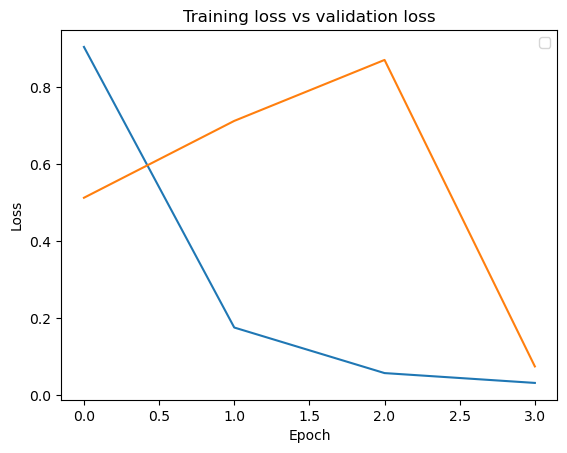

In [7]:
loss_function(history_basemodel)

In [8]:
def base_model(backbone, fine_tune, augmentation, preprocessing, dense_activation, optimizer, loss, epoch):
    
    base = backbone(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Keep its pretrained weights fixed
    base.trainable = fine_tune
    if fine_tune:
        for layer in base.layers[:-20]:
            layer.trainable = False

    model = Sequential()
    model.add(Input(shape=(224, 224, 3)))

    if augmentation is not None:
        model.add(augmentation)

    if preprocessing is not None:
        model.add(tf.keras.layers.Lambda(preprocessing))

    model.add(base)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(1, activation=dense_activation))

    model.compile(
            optimizer=optimizer,
            loss=loss,
            metrics=[
                tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                tf.keras.metrics.Precision(name="precision"),
                tf.keras.metrics.Recall(name="recall"),
                tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
                tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
                tf.keras.metrics.AUC(curve="PR", name="pr_auc")
            ]
        )

    history = model.fit(
            train_dataset,
            validation_data=validation_dataset,
            epochs= epoch
        )
    results = model.evaluate(test_dataset, return_dict=True)
    return model, history, results

In [9]:
resnet50_model, resnet50_history, resnet50_results = base_model(
    backbone= ResNet50,
    fine_tune= False,
    augmentation = None,
    preprocessing= resnet50_preprocessing,
    dense_activation="sigmoid",
    optimizer="adam",
    loss="binary_crossentropy",
    epoch=4,
)


Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 379s 6s/step - accuracy: 0.8030 - f1: 0.8105 - loss: 0.4445 - pr_auc: 0.8853 - precision: 0.7980 - recall: 0.8233 - roc_auc: 0.8867 - val_accuracy: 0.9038 - val_f1: 0.9084 - val_loss: 0.3180 - val_pr_auc: 0.9757 - val_precision: 0.9084 - val_recall: 0.9084 - val_roc_auc: 0.9729
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 362s 6s/step - accuracy: 0.9237 - f1: 0.9275 - loss: 0.2567 - pr_auc: 0.9791 - precision: 0.9024 - recall: 0.9540 - roc_auc: 0.9798 - val_accuracy: 0.9435 - val_f1: 0.9482 - val_loss: 0.2222 - val_pr_auc: 0.9917 - val_precision: 0.9148 - val_recall: 0.9841 - val_roc_auc: 0.9909
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 369s 6s/step - accuracy: 0.9425 - f1: 0.9451 - loss: 0.1959 - pr_auc: 0.9892 - precision: 0.9247 - recall: 0.9663 - roc_auc: 0.9891 - val_accuracy: 0.9603 - val_f1: 0.9613 - val_loss: 0.1905 - val_pr_auc: 0.9961 - val_precision: 0.9833 - val_recall: 0.9402 - val_roc_auc: 0.9956
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 369s 6s/step -

In [10]:
resnet50_model.save("../models/resnet50_model.keras")

C:\Users\msafw\AppData\Local\Temp\ipykernel_33284\3854882491.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


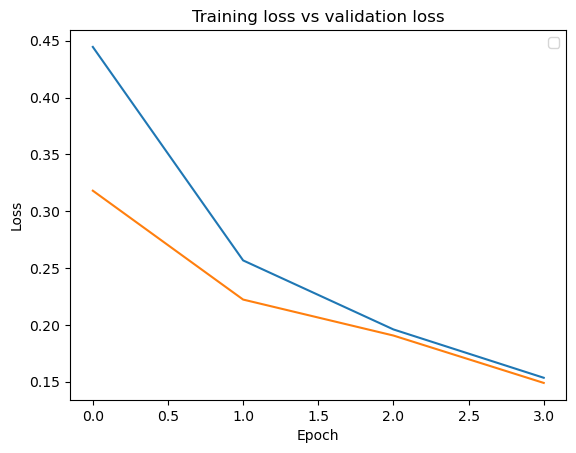

In [11]:
loss_function(resnet50_history)

In [12]:
vgg16_model, vgg16_history, vgg16_results = base_model(
    backbone= VGG16,
    fine_tune= False,
    augmentation = None,
    preprocessing=vgg16_preprocessing,
    dense_activation="sigmoid",
    optimizer="adam",
    loss="binary_crossentropy",
    epoch=4,
)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 780s 13s/step - accuracy: 0.5664 - f1: 0.5783 - loss: 0.9753 - pr_auc: 0.5627 - precision: 0.5753 - recall: 0.5812 - roc_auc: 0.5692 - val_accuracy: 0.7197 - val_f1: 0.7373 - val_loss: 0.5629 - val_pr_auc: 0.7615 - val_precision: 0.7259 - val_recall: 0.7490 - val_roc_auc: 0.7889
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 824s 14s/step - accuracy: 0.7884 - f1: 0.7958 - loss: 0.4571 - pr_auc: 0.8503 - precision: 0.7859 - recall: 0.8059 - roc_auc: 0.8647 - val_accuracy: 0.8368 - val_f1: 0.8408 - val_loss: 0.3531 - val_pr_auc: 0.9211 - val_precision: 0.8619 - val_recall: 0.8207 - val_roc_auc: 0.9254
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 790s 13s/step - accuracy: 0.8699 - f1: 0.8748 - loss: 0.3139 - pr_auc: 0.9388 - precision: 0.8614 - recall: 0.8887 - roc_auc: 0.9422 - val_accuracy: 0.8975 - val_f1: 0.9077 - val_loss: 0.2682 - val_pr_auc: 0.9628 - val_precision: 0.8607 - val_recall: 0.9602 - val_roc_auc: 0.9628
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 740s 12s/ste

C:\Users\msafw\AppData\Local\Temp\ipykernel_33284\3854882491.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


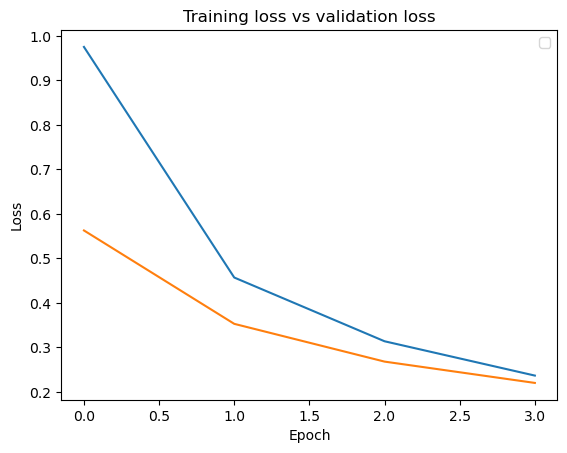

In [13]:
vgg16_model.save("../models/vgg16_model.keras")
loss_function(vgg16_history)

In [14]:
vgg16_aug_model, vgg16_aug_history, vgg16_aug_results = base_model(
    backbone= VGG16,
    fine_tune= False,
    augmentation = tf.keras.layers.RandomContrast(0.1) ,
    preprocessing=vgg16_preprocessing,
    dense_activation="sigmoid",
    optimizer="adam",
    loss="binary_crossentropy",
    epoch=4,
)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 894s 15s/step - accuracy: 0.6667 - f1: 0.6721 - loss: 0.7615 - pr_auc: 0.6903 - precision: 0.6763 - recall: 0.6680 - roc_auc: 0.7270 - val_accuracy: 0.7176 - val_f1: 0.7182 - val_loss: 0.6013 - val_pr_auc: 0.7867 - val_precision: 0.7544 - val_recall: 0.6853 - val_roc_auc: 0.7892
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 891s 15s/step - accuracy: 0.7994 - f1: 0.8029 - loss: 0.4204 - pr_auc: 0.8910 - precision: 0.8070 - recall: 0.7988 - roc_auc: 0.8891 - val_accuracy: 0.8159 - val_f1: 0.8346 - val_loss: 0.4079 - val_pr_auc: 0.9075 - val_precision: 0.7900 - val_recall: 0.8845 - val_roc_auc: 0.9027
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 889s 14s/step - accuracy: 0.8788 - f1: 0.8814 - loss: 0.2919 - pr_auc: 0.9535 - precision: 0.8823 - recall: 0.8805 - roc_auc: 0.9505 - val_accuracy: 0.8766 - val_f1: 0.8808 - val_loss: 0.2904 - val_pr_auc: 0.9527 - val_precision: 0.8934 - val_recall: 0.8685 - val_roc_auc: 0.9514
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 629s 11s/ste

C:\Users\msafw\AppData\Local\Temp\ipykernel_33284\3854882491.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


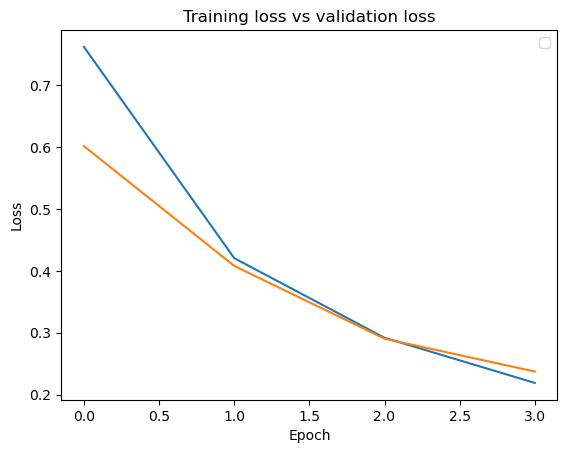

In [15]:
vgg16_aug_model.save("../models/vgg16_aug_model.keras")
loss_function(vgg16_aug_history)

In [16]:
efficientnetb0_model, efficientnetb0_history, efficientnetb0_results = base_model(
    backbone=EfficientNetB0,
    fine_tune = False,
    augmentation = None,
    preprocessing=None,
    dense_activation="sigmoid",
    optimizer="adam",
    loss="binary_crossentropy",
    epoch=4,
)


Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.7090 - f1: 0.7366 - loss: 0.5786 - pr_auc: 0.7754 - precision: 0.6857 - recall: 0.7957 - roc_auc: 0.7945 - val_accuracy: 0.8661 - val_f1: 0.8792 - val_loss: 0.4852 - val_pr_auc: 0.9243 - val_precision: 0.8351 - val_recall: 0.9283 - val_roc_auc: 0.9269
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.8652 - f1: 0.8757 - loss: 0.4384 - pr_auc: 0.9273 - precision: 0.8286 - recall: 0.9285 - roc_auc: 0.9348 - val_accuracy: 0.8975 - val_f1: 0.9067 - val_loss: 0.3872 - val_pr_auc: 0.9722 - val_precision: 0.8686 - val_recall: 0.9482 - val_roc_auc: 0.9692
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 147s 2s/step - accuracy: 0.8898 - f1: 0.8974 - loss: 0.3651 - pr_auc: 0.9570 - precision: 0.8562 - recall: 0.9428 - roc_auc: 0.9592 - val_accuracy: 0.9100 - val_f1: 0.9193 - val_loss: 0.3292 - val_pr_auc: 0.9819 - val_precision: 0.8688 - val_recall: 0.9761 - val_roc_auc: 0.9798
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 194s 3s/step - 

C:\Users\msafw\AppData\Local\Temp\ipykernel_33284\3854882491.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


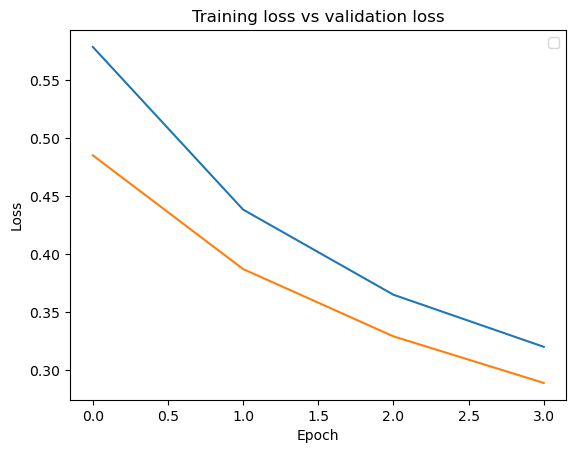

In [17]:
efficientnetb0_model.save("../models/efficientnetb0_model.keras")
loss_function(efficientnetb0_history)

In [18]:
mobilenetv2_model, mobilenetv2_history, mobilenetv2_results = base_model(
    backbone=MobileNetV2,
    fine_tune = False,
    augmentation = None,
    preprocessing=mobilenetv2_preprocessing,
    dense_activation="sigmoid",
    optimizer="adam",
    loss="binary_crossentropy",
    epoch=4,
)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 163s 2s/step - accuracy: 0.7382 - f1: 0.7574 - loss: 0.5294 - pr_auc: 0.8163 - precision: 0.7201 - recall: 0.7988 - roc_auc: 0.8228 - val_accuracy: 0.8243 - val_f1: 0.8444 - val_loss: 0.4184 - val_pr_auc: 0.9403 - val_precision: 0.7889 - val_recall: 0.9084 - val_roc_auc: 0.9323
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.8720 - f1: 0.8812 - loss: 0.3642 - pr_auc: 0.9472 - precision: 0.8386 - recall: 0.9285 - roc_auc: 0.9494 - val_accuracy: 0.8849 - val_f1: 0.8907 - val_loss: 0.3295 - val_pr_auc: 0.9676 - val_precision: 0.8889 - val_recall: 0.8924 - val_roc_auc: 0.9636
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.9086 - f1: 0.9134 - loss: 0.2928 - pr_auc: 0.9723 - precision: 0.8858 - recall: 0.9428 - roc_auc: 0.9729 - val_accuracy: 0.9059 - val_f1: 0.9123 - val_loss: 0.2784 - val_pr_auc: 0.9783 - val_precision: 0.8931 - val_recall: 0.9323 - val_roc_auc: 0.9755
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 190s 2s/step - 

C:\Users\msafw\AppData\Local\Temp\ipykernel_33284\3854882491.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


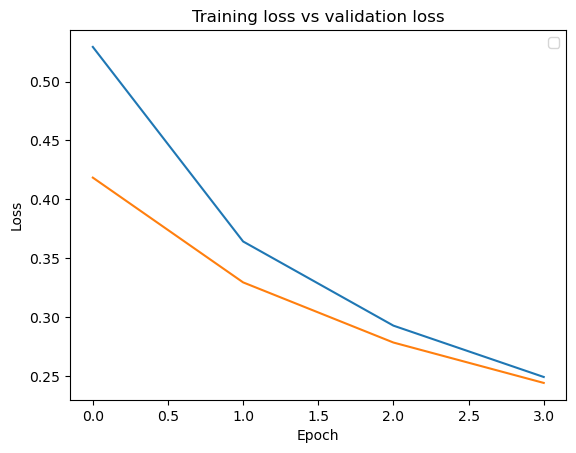

In [19]:
mobilenetv2_model.save("../models/mobilenetv2_model.keras")
loss_function(mobilenetv2_history)

In [20]:
mobilenetv2_tuned_model, mobilenetv2_tuned_history, mobilenetv2_tuned_results = base_model(
    backbone=MobileNetV2,
    fine_tune = True,
    augmentation = None,
    preprocessing=mobilenetv2_preprocessing,
    dense_activation="sigmoid",
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    epoch=4,
)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 254s 4s/step - accuracy: 0.8997 - f1: 0.9032 - loss: 0.2413 - pr_auc: 0.9717 - precision: 0.8915 - recall: 0.9152 - roc_auc: 0.9708 - val_accuracy: 0.9372 - val_f1: 0.9407 - val_loss: 0.2003 - val_pr_auc: 0.9901 - val_precision: 0.9333 - val_recall: 0.9482 - val_roc_auc: 0.9889
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 220s 4s/step - accuracy: 0.9922 - f1: 0.9924 - loss: 0.0405 - pr_auc: 0.9997 - precision: 0.9898 - recall: 0.9949 - roc_auc: 0.9996 - val_accuracy: 0.9582 - val_f1: 0.9609 - val_loss: 0.1310 - val_pr_auc: 0.9949 - val_precision: 0.9425 - val_recall: 0.9801 - val_roc_auc: 0.9944
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 207s 3s/step - accuracy: 0.9953 - f1: 0.9954 - loss: 0.0180 - pr_auc: 1.0000 - precision: 0.9939 - recall: 0.9969 - roc_auc: 1.0000 - val_accuracy: 0.9623 - val_f1: 0.9647 - val_loss: 0.1084 - val_pr_auc: 0.9968 - val_precision: 0.9498 - val_recall: 0.9801 - val_roc_auc: 0.9964
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 160s 3s/step - 

C:\Users\msafw\AppData\Local\Temp\ipykernel_33284\3854882491.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


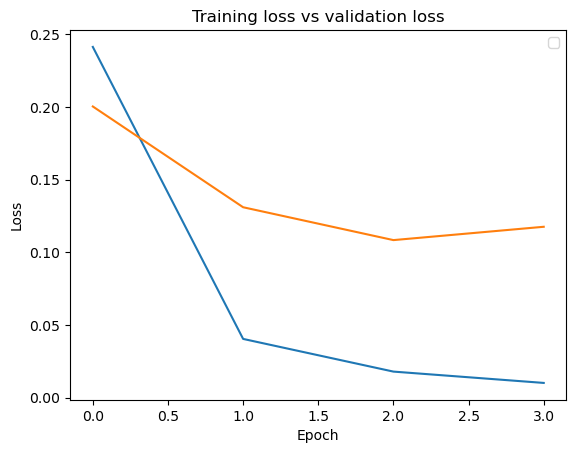

In [21]:
mobilenetv2_tuned_model.save("../models/mobilenetv2_tuned_model.keras")
loss_function(mobilenetv2_tuned_history)

In [22]:
# baseline_model = load_model("../models/custom_model.keras") 
# custom_model_results = baseline_model.evaluate(test_dataset, return_dict=True)
# print(custom_model_results)
path = Path("../models/custom_model.keras")
custom_model_file_size = round(path.stat().st_size / (1024**2),2)
custom_model_params = model.count_params()

#resnet50_model = load_model(
 #   "../models/resnet50_model.keras",
  #  custom_objects={
   #     "f1_m": tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
    #    "preprocess_input": resnet50_preprocessing,
    #}
#)
#resnet50_results = resnet50_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/resnet50_model.keras")
resnet50_file_size = round(path.stat().st_size / (1024**2),2)
resnet50_params = resnet50_model.count_params()

#vgg16_model = load_model("../models/vgg16_model.keras", custom_objects={"preprocess_input": vgg16_preprocessing})
#vgg16_results = vgg16_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/vgg16_model.keras")
vgg16_file_size = round(path.stat().st_size / (1024**2),2)
vgg16_params = vgg16_model.count_params()

#vgg16_aug_model = load_model("../models/vgg16_aug_model.keras", custom_objects={"preprocess_input": vgg16_preprocessing})
#vgg16_aug_results = vgg16_aug_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/vgg16_aug_model.keras")
vgg16_aug_file_size = round(path.stat().st_size / (1024**2),2)
vgg16_aug_params = vgg16_aug_model.count_params()

#efficientnetb0_model = load_model("../models/efficientnetb0_model.keras")
#efficientnetb0_results = efficientnetb0_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/efficientnetb0_model.keras")
efficientnetb0_file_size = round(path.stat().st_size / (1024**2),2)
efficientnetb0_params = efficientnetb0_model.count_params()

#mobilenetv2_model = load_model("../models/mobilenetv2_model.keras", custom_objects={"preprocess_input": mobilenetv2_preprocessing})
#mobilenetv2_results = mobilenetv2_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/mobilenetv2_model.keras")
mobilenetv2_file_size = round(path.stat().st_size / (1024**2),2)
mobilenetv2_params = mobilenetv2_model.count_params()

#mobilenetv2_tuned_model = load_model("../models/mobilenetv2_tuned_model.keras", custom_objects={
#        "f1_m": tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
#        "preprocess_input": mobilenetv2_preprocessing,
#    })
#mobilenetv2_tuned_results = mobilenetv2_tuned_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/mobilenetv2_tuned_model.keras")
mobilenetv2_tuned_file_size = round(path.stat().st_size / (1024**2),2)
mobilenetv2_tuned_params = mobilenetv2_tuned_model.count_params()



In [23]:
comparsion_table = pd.DataFrame({
    "Model": ["Custom_Model", "ResNet50", "VGG16", "VGG16_Aug", "EfficientnetB0", "MobilenetV2", "MobilenetV2_tuned"],
    "Accuracy": [custom_model_results["accuracy"], resnet50_results["accuracy"], vgg16_results["accuracy"], vgg16_aug_results["accuracy"], efficientnetb0_results["accuracy"], mobilenetv2_results["accuracy"], mobilenetv2_tuned_results["accuracy"]],
    "F1": [custom_model_results["f1"], resnet50_results["f1"], vgg16_results["f1"], vgg16_aug_results["f1"], efficientnetb0_results["f1"], mobilenetv2_results["f1"], mobilenetv2_tuned_results["f1"]],
    "Recall": [custom_model_results["recall"], resnet50_results["recall"], vgg16_results["recall"], vgg16_aug_results["recall"], efficientnetb0_results["recall"], mobilenetv2_results["recall"], mobilenetv2_tuned_results["recall"]],
    "Precision": [custom_model_results["precision"], resnet50_results["precision"], vgg16_results["precision"], vgg16_aug_results["precision"], efficientnetb0_results["precision"], mobilenetv2_results["precision"], mobilenetv2_tuned_results["precision"]],
    "ROC_AUC": [custom_model_results["roc_auc"], resnet50_results["roc_auc"], vgg16_results["roc_auc"], vgg16_aug_results["roc_auc"], efficientnetb0_results["roc_auc"], mobilenetv2_results["roc_auc"], mobilenetv2_tuned_results["roc_auc"]],
    "PR_AUC": [custom_model_results["pr_auc"], resnet50_results["pr_auc"], vgg16_results["pr_auc"], vgg16_aug_results["pr_auc"], efficientnetb0_results["pr_auc"], mobilenetv2_results["pr_auc"], mobilenetv2_tuned_results["pr_auc"]],
    "File_Size_MB": [custom_model_file_size, resnet50_file_size, vgg16_file_size, vgg16_aug_file_size, efficientnetb0_file_size, mobilenetv2_file_size, mobilenetv2_tuned_file_size],
    "Parameters": [custom_model_params, resnet50_params, vgg16_params, vgg16_aug_params, efficientnetb0_params, mobilenetv2_params, mobilenetv2_tuned_params]
})

In [25]:
comparsion_table.to_csv("../data/comparsion.csv")

In [24]:
comparsion_table

,Model,Accuracy,F1,Recall,Precision,ROC_AUC,PR_AUC,File_Size_MB,Parameters
0,Custom_Model,0.939699,0.943574,0.980456,0.909366,0.991716,0.988585,0.89,73825
1,ResNet50,0.969849,0.971429,0.996743,0.947368,0.996922,0.997075,90.63,23589761
2,VGG16,0.889447,0.897833,0.944625,0.855457,0.961996,0.959676,56.22,14715201
3,VGG16_Aug,0.906198,0.911111,0.934853,0.888545,0.970122,0.968528,56.23,14715201
4,EfficientnetB0,0.926298,0.931250,0.970684,0.894895,0.980563,0.982182,16.27,4050852
5,MobilenetV2,0.921273,0.923825,0.928339,0.919355,0.983506,0.984694,9.19,2259265
6,MobilenetV2_tuned,0.954774,0.957746,0.996743,0.921687,0.996288,0.996394,18.40,2259265


In [26]:
# Your trained model
model = mobilenetv2_tuned_model

img_size = (224, 224)

# Use the same preprocessing already included in your model.
# Do not preprocess the image again outside the model.

# Last convolutional layer in MobileNetV2
last_conv_layer_name = "Conv_1"

# Path to one of your test images

img_path = random.choice(glob.glob("../data/testing/flip/*.jpg"))


In [27]:
def get_img_array(img_path, size=(224, 224)):
    # Load and resize the image to 224 × 224
    img = keras.utils.load_img(img_path, target_size=size)

    # Convert to a float32 array: (224, 224, 3)
    array = keras.utils.img_to_array(img)

    # Add the batch dimension: (1, 224, 224, 3)
    array = np.expand_dims(array, axis=0)

    return array

In [38]:
img_array = get_img_array(img_path, size=(224, 224))

In [39]:
def make_gradcam_heatmap(img_array, model):
    # Find MobileNetV2 inside your model
    base_model = model.get_layer("mobilenetv2_1.00_224")
    base_index = model.layers.index(base_model)

    x = tf.convert_to_tensor(img_array, dtype=tf.float32)

    # Apply preprocessing
    for layer in model.layers[:base_index]:
        x = layer(x, training=False)

    # Get MobileNetV2's feature maps
    features = base_model(x, training=False)

    with tf.GradientTape() as tape:
        tape.watch(features)
        prediction = features

        # Apply pooling and the final Dense layer
        for layer in model.layers[base_index + 1:]:
            prediction = layer(prediction, training=False)

        # Explain the predicted class
        probability = prediction[0, 0]
        score = tf.where(probability >= 0.5, probability, 1 - probability)

    # Calculate the importance of each feature map
    gradients = tape.gradient(score, features)
    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    # Combine and normalize
    heatmap = tf.reduce_sum(features[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = tf.math.divide_no_nan(heatmap, tf.reduce_max(heatmap))

    return heatmap.numpy()

In [40]:
heatmap = make_gradcam_heatmap(img_array, model)

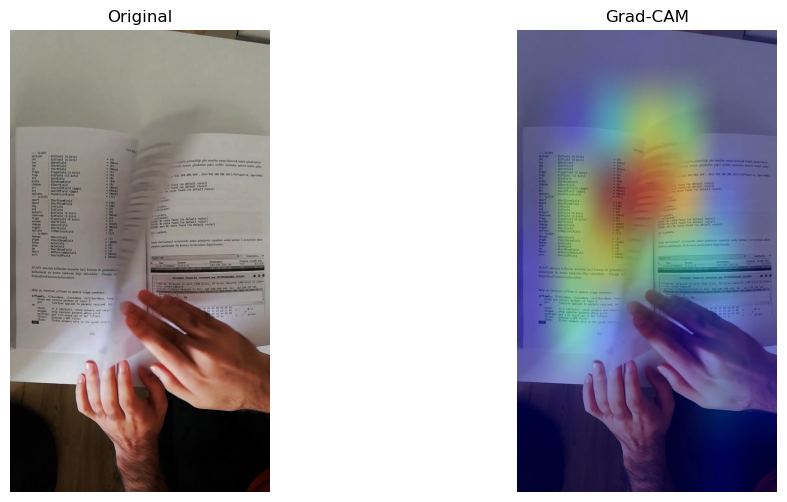

In [41]:

def save_and_display_gradcam(img_path, heatmap,
                             cam_path="../reports/cam.jpg", alpha=0.4):
    # Load the original image
    original = keras.utils.load_img(img_path)
    img = keras.utils.img_to_array(original)

    # Convert the heatmap to RGB colours
    heatmap = np.uint8(255 * np.clip(heatmap, 0, 1))
    colored_heatmap = plt.get_cmap("jet")(heatmap)[..., :3]
    colored_heatmap = np.uint8(255 * colored_heatmap)

    # Resize the heatmap to match the original image
    colored_heatmap = keras.utils.array_to_img(
        colored_heatmap, scale=False
    )
    colored_heatmap = colored_heatmap.resize(
        (img.shape[1], img.shape[0])
    )
    colored_heatmap = keras.utils.img_to_array(colored_heatmap)

    # Blend the heatmap with the original image
    overlay = (1 - alpha) * img + alpha * colored_heatmap
    overlay = keras.utils.array_to_img(overlay, scale=False)

    # Save the overlay
    Path(cam_path).parent.mkdir(parents=True, exist_ok=True)
    overlay.save(cam_path)

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(img.astype("uint8"))
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(overlay)
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.show()
save_and_display_gradcam(img_path, heatmap)